# SCIKIT-LEARN MASTERY — NOTEBOOK 5
## Chapters 21–25: Random Forest Integration → Gradient Boosting → Model Selection Overview → Cross-Validation Deeply → Hyperparameter Tuning

Continuing directly from Notebook 4.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Chapters 1–20 *(Notebooks 1–4)*
- [x] Random Forest Integration (into the full ecosystem)
- [x] Gradient Boosting
- [x] Model Selection Overview
- [x] Cross Validation (deep dive)
- [x] Hyperparameter Tuning


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
np.random.seed(42)


---
# CHAPTER 21 — RANDOM FOREST INTEGRATION

## 1. Concept
*(Random Forest theory is assumed already known.)* This chapter connects your existing Random Forest knowledge to the **full ecosystem** built across Notebooks 2–4:

```
Pandas (raw data)
   ↓
ColumnTransformer (Ch 10)
   ↓
Pipeline (Ch 11)
   ↓
RandomForestClassifier
   ↓
Cross Validation (Ch 24)
   ↓
GridSearchCV (Ch 25)
   ↓
Evaluation (Notebook 6)
   ↓
Joblib persistence (Ch 66)
```

## 2. A Production-Style Example, End to End


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Realistic mixed synthetic dataset (same style as Notebook 3's Titanic-like data)
np.random.seed(21)
n = 1000
df_rf = pd.DataFrame({
    "tenure_months": np.random.exponential(24, n).round(1),
    "monthly_charges": np.random.exponential(60, n).round(2),
    "contract": np.random.choice(["Month-to-month", "One year", "Two year"], n, p=[0.5, 0.3, 0.2]),
    "payment_method": np.random.choice(["Credit card", "Bank transfer", "Check"], n),
})
churn_logit = -1 + (df_rf["contract"] == "Month-to-month") * 1.3 - df_rf["tenure_months"] * 0.03
df_rf["churned"] = (np.random.rand(n) < 1 / (1 + np.exp(-churn_logit))).astype(int)
df_rf.loc[np.random.choice(n, 40, replace=False), "monthly_charges"] = np.nan

X_rf = df_rf.drop(columns="churned")
y_rf = df_rf["churned"]

numerical_cols_rf = ["tenure_months", "monthly_charges"]
categorical_cols_rf = ["contract", "payment_method"]

preprocessor_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical_cols_rf),   # NOTE: Random Forest needs NO scaling
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols_rf),
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)),
])

cv_scores = cross_val_score(rf_pipeline, X_rf, y_rf, cv=5, scoring="roc_auc")
print("5-fold CV ROC-AUC scores:", cv_scores.round(4))
print(f"Mean: {cv_scores.mean():.4f}  Std: {cv_scores.std():.4f}")


5-fold CV ROC-AUC scores: [0.7396 0.7324 0.7568 0.7437 0.6821]
Mean: 0.7309  Std: 0.0257


### Line-by-Line Explanation
- Note the preprocessor has **no scaler** in the numerical branch — deliberately, since Random Forest doesn't need it (Chapter 5's lesson, applied here). Including a scaler wouldn't hurt correctness, but it's wasted computation and, more importantly, understanding *why* it's omittable is the actual interview-relevant knowledge.
- `cross_val_score(rf_pipeline, X_rf, y_rf, cv=5, scoring="roc_auc")` — passing the **entire pipeline** (not just the classifier) to `cross_val_score` is what makes this correctly leakage-safe: each of the 5 folds independently refits the *entire* preprocessing + model pipeline using only that fold's training portion, exactly the guarantee established in Chapter 11.

### Feature Importance, Traced Back Through the Pipeline


In [3]:
rf_pipeline.fit(X_rf, y_rf)

feature_names_rf = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances_rf = rf_pipeline.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({"feature": feature_names_rf, "importance": importances_rf}).sort_values("importance", ascending=False)
print(importance_df)


                             feature  importance
0                 num__tenure_months    0.421761
1               num__monthly_charges    0.279350
2       cat__contract_Month-to-month    0.160033
3             cat__contract_One year    0.061663
4             cat__contract_Two year    0.031682
5  cat__payment_method_Bank transfer    0.016759
7    cat__payment_method_Credit card    0.014906
6          cat__payment_method_Check    0.013846


### Interpretation
`tenure_months` and the "Month-to-month" contract indicator should dominate importance here — consistent with how the synthetic churn signal was constructed, a useful sanity check confirming the whole pipeline (preprocessing → model → importance extraction) is wired correctly end to end.

### Common Mistakes
- Fitting `RandomForestClassifier()` directly on raw, un-preprocessed data outside a Pipeline — while Random Forest handles unscaled numerical data fine, it still cannot handle raw string categorical columns or missing values (`NaN`) without an error; the preprocessing steps remain mandatory, even though *scaling specifically* is not.
- Passing only the classifier (not the full pipeline) to `cross_val_score`/`GridSearchCV` after preprocessing outside — reintroduces the exact leakage Chapter 11 exists to prevent.

### Interview Insight
**Q: Does Random Forest need a `ColumnTransformer`/`Pipeline`, given that it doesn't need feature scaling?**
A: Yes — not needing scaling only removes one specific preprocessing step; Random Forest still cannot directly consume raw categorical strings or missing values, so imputation and encoding remain mandatory. The Pipeline's leakage-prevention role (ensuring preprocessing is refit correctly per cross-validation fold) is also entirely independent of whether scaling is involved — it applies identically regardless of model family.

### Quiz (Chapter 21)
1. Why does the numerical branch of this ColumnTransformer omit a scaler, and what does Random Forest still need preprocessing for regardless?
2. Why must the *entire pipeline* (not just the classifier) be passed to `cross_val_score`?


---
# CHAPTER 22 — GRADIENT BOOSTING

## 1. Concept
Gradient Boosting builds trees **sequentially**, where each new tree is fit to the **residual errors** of the ensemble so far (in a gradient-descent-like sense, hence the name) — a fundamentally different construction from Random Forest's independent, parallel trees, and generally more sensitive to its hyperparameters as a result.

## 2. Key Parameters
| Parameter | Effect |
|---|---|
| `learning_rate` | How much each new tree's correction is "trusted" — smaller = more conservative, needs more `n_estimators` to compensate, but often generalizes better |
| `n_estimators` | Number of sequential trees — more can improve fit but risks overfitting if `learning_rate` isn't correspondingly small |
| `max_depth` | Depth of each individual tree — boosting trees are typically kept **shallow** (depth 3–6), unlike Random Forest's often-deeper trees, since boosting's sequential error-correction supplies the complexity |
| `max_leaf_nodes` | Alternative complexity control to `max_depth` |
| `min_samples_leaf` | Regularization — larger values smooth predictions |
| `l2_regularization` | (`HistGradientBoostingClassifier` only) direct L2 penalty on leaf values |

## 3. `GradientBoostingClassifier` vs `HistGradientBoostingClassifier`
`HistGradientBoosting*` bins continuous features into histograms before finding splits (inspired by, and roughly competitive with, LightGBM's approach) — **dramatically faster** on larger datasets than the original `GradientBoostingClassifier`, with very similar or better accuracy in most cases. For any dataset beyond a few thousand rows, `HistGradientBoosting*` is generally the better default.


In [4]:
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import time

X_gb, y_gb = make_classification(n_samples=5000, n_features=15, n_informative=8, random_state=42)
X_gb_train, X_gb_test, y_gb_train, y_gb_test = train_test_split(X_gb, y_gb, test_size=0.25, random_state=42)

start = time.time()
gb = GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42)
gb.fit(X_gb_train, y_gb_train)
gb_time = time.time() - start
gb_auc = roc_auc_score(y_gb_test, gb.predict_proba(X_gb_test)[:, 1])

start = time.time()
hgb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1, random_state=42)
hgb.fit(X_gb_train, y_gb_train)
hgb_time = time.time() - start
hgb_auc = roc_auc_score(y_gb_test, hgb.predict_proba(X_gb_test)[:, 1])

print(f"{'Model':<28}{'Fit time (s)':>14}{'Test ROC-AUC':>16}")
print(f"{'GradientBoosting':<28}{gb_time:>14.3f}{gb_auc:>16.4f}")
print(f"{'HistGradientBoosting':<28}{hgb_time:>14.3f}{hgb_auc:>16.4f}")


Model                         Fit time (s)    Test ROC-AUC
GradientBoosting                     2.994          0.9718
HistGradientBoosting                 0.104          0.9685


### The `learning_rate` / `n_estimators` Tradeoff, Demonstrated


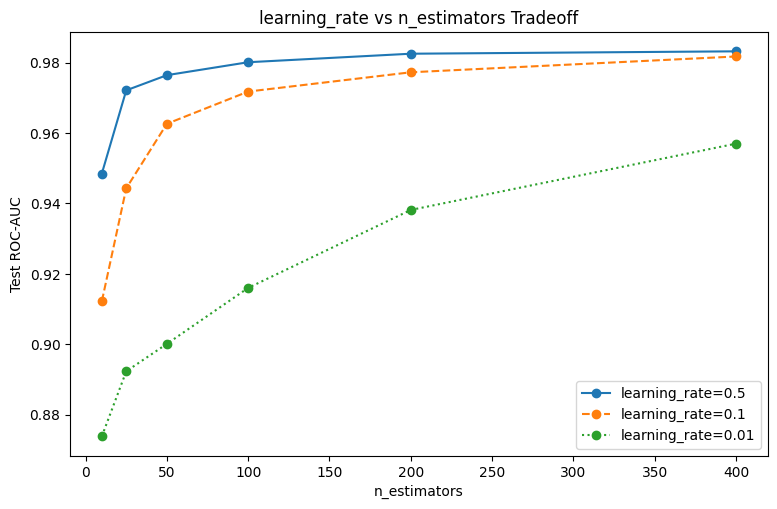

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))

for lr, style in [(0.5, "-"), (0.1, "--"), (0.01, ":")]:
    n_est_range = [10, 25, 50, 100, 200, 400]
    test_aucs = []
    for n_est in n_est_range:
        model = GradientBoostingClassifier(n_estimators=n_est, learning_rate=lr, max_depth=3, random_state=42)
        model.fit(X_gb_train, y_gb_train)
        test_aucs.append(roc_auc_score(y_gb_test, model.predict_proba(X_gb_test)[:, 1]))
    ax.plot(n_est_range, test_aucs, style, marker="o", label=f"learning_rate={lr}")

ax.set_xlabel("n_estimators")
ax.set_ylabel("Test ROC-AUC")
ax.set_title("learning_rate vs n_estimators Tradeoff")
ax.legend()
plt.show()


### Interpretation
- **High learning rate (0.5)**: reaches good performance with few trees, but risks overfitting/instability if pushed to many estimators (each correction step is large and aggressive).
- **Low learning rate (0.01)**: needs many more trees to reach comparable performance, but each individual correction step is small and conservative — often the more stable, better-generalizing choice, at the cost of needing more `n_estimators` (and therefore more training time) to get there.
- **Moderate (0.1)**: a common practical default, balancing the two.

This is precisely the "more trees, smaller steps" tradeoff that motivates why `learning_rate` and `n_estimators` are almost always tuned **together**, never independently (a direct callback to Chapter 20's boosting bias-reduction mechanism, and a preview of Chapter 25's `GridSearchCV`).

### Common Mistakes
- Tuning `n_estimators` without also considering `learning_rate` (or vice versa) — they're fundamentally coupled; a large `n_estimators` search is often wasted if `learning_rate` is left at an unsuitable fixed value, and vice versa.
- Using deep trees (`max_depth=10+`) within a boosting ensemble — unlike Random Forest, boosting's individual trees are meant to be weak/shallow learners; deep boosting trees combined with many estimators is a strong overfitting risk.
- Defaulting to `GradientBoostingClassifier` on a large dataset without at least comparing `HistGradientBoostingClassifier`'s speed/performance — often a near-free upgrade.

### Best Practices
- Keep individual tree depth shallow (3–6) for boosting.
- Tune `learning_rate` and `n_estimators` jointly (Chapter 25).
- Default to `HistGradientBoostingClassifier` for anything beyond a few thousand rows.

### Interview Insight
**Q: Why is a lower `learning_rate` combined with more `n_estimators` often preferred over a higher `learning_rate` with fewer trees, even though both can reach similar training performance?**
A: A lower learning rate makes each tree's correction to the ensemble smaller and more conservative, which tends to produce a smoother, more gradual approach to the optimal fit and generally generalizes better to unseen data — it's less likely to make a large, potentially wrong correction based on noise in any single boosting round. The tradeoff is purely computational: more trees are needed to reach comparable training performance, meaning longer training time, which is why the choice is a genuine tradeoff to tune, not a free win in one direction.

### Mini Exercise
Repeat the `learning_rate`/`n_estimators` sweep using `HistGradientBoostingClassifier` (note: its parameter is called `max_iter`, not `n_estimators`) and compare the resulting curve shapes.

### Quiz (Chapter 22)
1. Why are individual trees in a boosting ensemble typically kept shallow, unlike Random Forest's often-deeper trees?
2. Why must `learning_rate` and `n_estimators` be tuned jointly rather than independently?
3. When is `HistGradientBoostingClassifier` generally preferred over `GradientBoostingClassifier`?


---
# CHAPTER 23 — MODEL SELECTION (sklearn.model_selection OVERVIEW)

## 1. Concept
`sklearn.model_selection` provides every splitting strategy needed for honest evaluation — beyond the basic `train_test_split` (Chapter 4) and default K-Fold cross-validation, specialized splitters handle grouped, stratified, repeated, and time-ordered data correctly.

## 2. The Splitter Roster
| Splitter | Use case |
|---|---|
| `KFold` | Standard K-fold, no special structure |
| `StratifiedKFold` | Preserves class proportions in every fold — the default, correct choice for classification |
| `GroupKFold` | Ensures all rows from the same group (e.g., same patient/customer) stay entirely within one fold — Chapter 55 |
| `StratifiedGroupKFold` | Combines both: class balance preserved AND groups kept intact |
| `RepeatedKFold` / `RepeatedStratifiedKFold` | Runs K-fold multiple times with different random splits, for a more stable performance estimate |
| `LeaveOneOut` | Each fold holds out exactly 1 sample — extremely thorough but computationally expensive; mainly for very small datasets |
| `TimeSeriesSplit` | Respects temporal order — never validates on data that precedes its training data — Chapter 54 |


In [6]:
from sklearn.model_selection import KFold, StratifiedKFold, GroupKFold, TimeSeriesSplit

X_ms, y_ms = make_classification(n_samples=20, weights=[0.8, 0.2], random_state=1)   # tiny, imbalanced, for visible fold structure

print("=== Plain KFold (does NOT preserve class balance) ===")
for i, (train_idx, val_idx) in enumerate(KFold(n_splits=4).split(X_ms, y_ms)):
    print(f"Fold {i}: val class balance = {y_ms[val_idx].mean():.2f}  (val size={len(val_idx)})")

print("\n=== StratifiedKFold (DOES preserve class balance) ===")
for i, (train_idx, val_idx) in enumerate(StratifiedKFold(n_splits=4).split(X_ms, y_ms)):
    print(f"Fold {i}: val class balance = {y_ms[val_idx].mean():.2f}  (val size={len(val_idx)})")


=== Plain KFold (does NOT preserve class balance) ===
Fold 0: val class balance = 0.00  (val size=5)
Fold 1: val class balance = 0.20  (val size=5)
Fold 2: val class balance = 0.60  (val size=5)
Fold 3: val class balance = 0.20  (val size=5)

=== StratifiedKFold (DOES preserve class balance) ===
Fold 0: val class balance = 0.20  (val size=5)
Fold 1: val class balance = 0.20  (val size=5)
Fold 2: val class balance = 0.20  (val size=5)
Fold 3: val class balance = 0.40  (val size=5)


### Interpretation
Plain `KFold`'s per-fold class balance visibly varies more than `StratifiedKFold`'s — on a small or imbalanced dataset, this variance can meaningfully distort cross-validation score estimates fold to fold, purely from unlucky splitting rather than genuine model performance differences. **`StratifiedKFold` is the correct default for classification**, and is in fact what `cross_val_score`/`GridSearchCV` use automatically under the hood when given a classifier and integer `cv=` — worth knowing this automatic behavior explicitly rather than assuming plain KFold is silently used.

### `GroupKFold` — Preventing Group Leakage, Demonstrated


In [7]:
# Simulate 5 "patients," each with several repeated measurements -- rows from the SAME
# patient must never be split across train and validation, or the model could partly
# "memorize" that patient rather than genuinely generalizing to NEW patients
patient_ids = np.repeat(np.arange(5), 4)   # patient 0,0,0,0,1,1,1,1,...
X_group = np.random.randn(20, 3)
y_group = np.random.randint(0, 2, 20)

print("=== GroupKFold: same patient NEVER split across train/val ===")
for i, (train_idx, val_idx) in enumerate(GroupKFold(n_splits=5).split(X_group, y_group, groups=patient_ids)):
    train_patients = set(patient_ids[train_idx])
    val_patients = set(patient_ids[val_idx])
    overlap = train_patients & val_patients
    print(f"Fold {i}: val patients={val_patients}, overlap with train={overlap if overlap else 'NONE (correct)'}")


=== GroupKFold: same patient NEVER split across train/val ===
Fold 0: val patients={np.int64(4)}, overlap with train=NONE (correct)
Fold 1: val patients={np.int64(3)}, overlap with train=NONE (correct)
Fold 2: val patients={np.int64(2)}, overlap with train=NONE (correct)
Fold 3: val patients={np.int64(1)}, overlap with train=NONE (correct)
Fold 4: val patients={np.int64(0)}, overlap with train=NONE (correct)


### Internal Working
`GroupKFold` takes a `groups` array (same length as `X`) and guarantees every fold's validation set contains entirely different group IDs from its training set — critical whenever multiple rows genuinely belong to the "same real-world unit" (patient, customer, image-from-the-same-person), since a model that's seen *any* row from a given group during training could partially "cheat" by recognizing that group's other rows, rather than genuinely generalizing to unseen groups (Chapter 55 covers this leakage pattern in full depth with realistic business examples).

### Common Mistakes
- Using plain `KFold` for classification instead of `StratifiedKFold` — usually a minor issue on large, balanced datasets, but a real source of noisy/misleading CV estimates on small or imbalanced ones.
- Using plain `KFold`/`StratifiedKFold` on grouped data (multiple rows per customer/patient) — silently allows the exact group-leakage pattern `GroupKFold` exists to prevent.
- Not realizing `cross_val_score`/`GridSearchCV` already default to `StratifiedKFold` for classifiers when given a plain integer `cv=` — no need to always construct the splitter object explicitly unless you need a *different* strategy.

### Best Practices
- Default to `StratifiedKFold` for classification (or just pass an integer `cv=`, which triggers this automatically).
- Identify whether your data has a natural grouping structure (multiple rows per real-world entity) **before** choosing a splitter — this is a data-understanding question, not a code-syntax question, and getting it wrong produces a cross-validation estimate that looks great but doesn't reflect genuine future performance.

### Interview Insight
**Q: You have a dataset of medical images where each of 200 patients contributed 5 images each. A model cross-validated with plain `StratifiedKFold` shows excellent performance. What's your concern?**
A: `StratifiedKFold` preserves class balance but has no concept of the patient-level grouping — it's entirely possible (likely, even) for some of a given patient's 5 images to land in the training fold and others in the validation fold for that same split. If the model can pick up on patient-specific visual characteristics unrelated to the actual diagnostic signal, it could achieve inflated validation performance by partially recognizing the *patient*, not learning the genuine diagnostic pattern — this would not generalize to a truly new, unseen patient in production. `GroupKFold` (grouping by patient ID) is the correct splitter here, ensuring every fold's validation patients are never also present in that fold's training data.

### Mini Exercise
Rebuild the patient example with `StratifiedGroupKFold` instead of `GroupKFold`, and confirm it maintains both properties (group integrity AND class balance) simultaneously.

### Quiz (Chapter 23)
1. Why does `StratifiedKFold` produce more stable cross-validation estimates than plain `KFold` for classification, especially on imbalanced data?
2. What specific leakage risk does `GroupKFold` prevent, and give a concrete real-world example.
3. Which splitter does `cross_val_score` use by default for a classifier, when given a plain integer `cv=`?


---
# CHAPTER 24 — CROSS VALIDATION DEEPLY

## 1. Concept

```
Dataset
  │
  ├── Fold 1 (held out) │ Fold 2,3,4,5 (train) → score₁
  ├── Fold 2 (held out) │ Fold 1,3,4,5 (train) → score₂
  ├── Fold 3 (held out) │ Fold 1,2,4,5 (train) → score₃
  ├── Fold 4 (held out) │ Fold 1,2,3,5 (train) → score₄
  └── Fold 5 (held out) │ Fold 1,2,3,4 (train) → score₅
                              ↓
                    mean(scores), std(scores)
```

Every sample gets used for validation **exactly once** and for training **k-1 times** — cross-validation squeezes a more reliable performance estimate out of limited data than a single train/validation split would, by averaging over `k` different train/validation partitions instead of trusting just one.

## 2. `cross_val_score` vs `cross_validate` vs `cross_val_predict`


In [8]:
from sklearn.model_selection import cross_val_score, cross_validate, cross_val_predict
from sklearn.ensemble import RandomForestClassifier

X_cv, y_cv = make_classification(n_samples=1000, n_features=10, random_state=42)
model_cv = RandomForestClassifier(n_estimators=100, random_state=42)

# cross_val_score -- simplest: just an array of scores, one metric
scores = cross_val_score(model_cv, X_cv, y_cv, cv=5, scoring="accuracy")
print("cross_val_score:", scores.round(4), " mean:", scores.mean().round(4), " std:", scores.std().round(4))

# cross_validate -- richer: multiple metrics AND timing info AND (optionally) the fitted estimators themselves
results = cross_validate(
    model_cv, X_cv, y_cv, cv=5,
    scoring=["accuracy", "roc_auc", "f1"],
    return_train_score=True,       # compare train vs val score per fold -- directly reveals overfitting per fold
    return_estimator=True,          # keep each fold's fitted model, e.g. for later ensembling or inspection
)
print("\ncross_validate results (keys):", list(results.keys()))
print("\nPer-fold test accuracy:", results["test_accuracy"].round(4))
print("Per-fold train accuracy:", results["train_accuracy"].round(4))
print("(A large train-vs-test gap per fold is a per-fold overfitting signal.)")


cross_val_score: [0.915 0.895 0.915 0.885 0.91 ]  mean: 0.904  std: 0.012

cross_validate results (keys): ['fit_time', 'score_time', 'estimator', 'test_accuracy', 'train_accuracy', 'test_roc_auc', 'train_roc_auc', 'test_f1', 'train_f1']

Per-fold test accuracy: [0.915 0.895 0.915 0.885 0.91 ]
Per-fold train accuracy: [1. 1. 1. 1. 1.]
(A large train-vs-test gap per fold is a per-fold overfitting signal.)


In [9]:
# cross_val_predict -- returns out-of-fold PREDICTIONS for every sample (not scores)
# each prediction comes from a model that did NOT see that specific sample during training
oof_preds = cross_val_predict(model_cv, X_cv, y_cv, cv=5)
print("\ncross_val_predict shape:", oof_preds.shape, "-- one prediction per ORIGINAL sample")
print("This is useful for: building a confusion matrix from genuinely held-out predictions,")
print("or as input features for a StackingClassifier's meta-model (Chapter 20).")



cross_val_predict shape: (1000,) -- one prediction per ORIGINAL sample
This is useful for: building a confusion matrix from genuinely held-out predictions,
or as input features for a StackingClassifier's meta-model (Chapter 20).


### Line-by-Line Explanation
- `return_train_score=True` — off by default (computing it costs extra time), but genuinely valuable: comparing `train_accuracy` to `test_accuracy` **per fold** directly diagnoses overfitting without needing a separate held-out set.
- `cross_val_predict` — a common point of confusion: it does **not** return performance scores; it returns actual out-of-fold predictions, reassembled into the original sample order, useful for downstream analysis (confusion matrices, stacking) rather than direct evaluation summary statistics.

## 3. Interpreting Mean and Standard Deviation


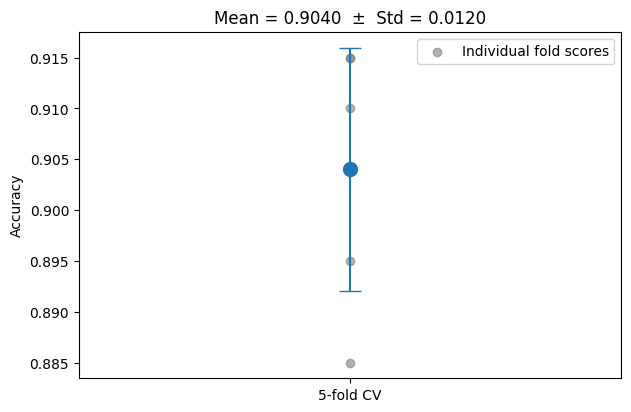

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(["5-fold CV"], [scores.mean()], yerr=[scores.std()], fmt="o", capsize=8, markersize=10, color="tab:blue")
ax.scatter([0]*5, scores, color="gray", alpha=0.6, zorder=0, label="Individual fold scores")
ax.set_ylabel("Accuracy")
ax.set_title(f"Mean = {scores.mean():.4f}  ±  Std = {scores.std():.4f}")
ax.legend()
plt.show()


### Interpretation
The **mean** is the headline performance estimate; the **standard deviation** across folds tells you how *stable* that estimate is — a high std (fold scores varying widely) suggests the model's performance is sensitive to exactly which data it happens to see, a useful red flag on small datasets or models prone to instability (e.g., a single unconstrained Decision Tree would typically show much higher fold-to-fold variance than a Random Forest here). **A higher mean CV score does not automatically mean a better model** if it comes with dramatically higher variance — this exact nuance is one of this course's flagged "interview traps" (Chapter 98 equivalent).

### Common Mistakes
- Reporting only the mean CV score, discarding the standard deviation — hides genuinely important information about estimate reliability.
- Assuming cross-validation eliminates overfitting entirely — it gives a more *honest estimate* of generalization than a single split, but a model can still be genuinely overfit to the *entire* dataset in a way cross-validation (which still only uses that same dataset) cannot detect; only genuinely new, out-of-distribution data can reveal that.
- Confusing `cross_val_predict`'s output (predictions) with `cross_val_score`'s output (scores) — a real, easy mixup given the similar names.

### Best Practices
- Always report mean **and** standard deviation together.
- Use `cross_validate` with `return_train_score=True` during model development to catch per-fold overfitting directly.
- Use `cross_val_predict` specifically when you need actual out-of-fold predictions (e.g., for a confusion matrix built from genuinely unseen-during-training predictions, or stacking).

### Interview Insight
**Q: Does cross-validation eliminate overfitting?**
A: No — cross-validation provides a more reliable *estimate* of a model's generalization performance than a single train/validation split, by averaging over multiple different partitions of the same dataset. But every fold's "validation" data still comes from the same overall dataset the model was developed against; if the *entire* dataset itself has some systematic quirk, bias, or leakage issue, cross-validation cannot detect that, since it has no access to genuinely external data. Cross-validation reduces the *variance* of your performance estimate from an unlucky/lucky single split — it does not, and cannot, guarantee the model will generalize to truly new, out-of-distribution data.

### Mini Exercise
Compare `cross_val_score`'s mean/std for `RandomForestClassifier` versus a single unconstrained `DecisionTreeClassifier()` on the same data — expect the single tree to show a lower mean and/or a notably higher standard deviation across folds, a direct empirical illustration of ensembling's variance-reduction property (Chapter 20).

### Quiz (Chapter 24)
1. Why does averaging over K folds give a more reliable estimate than a single train/validation split?
2. What does `cross_val_predict` return that's fundamentally different from `cross_val_score`?
3. Why doesn't cross-validation guarantee a model isn't overfit to the dataset as a whole?
4. Why should you always report standard deviation alongside the mean CV score?


---
# CHAPTER 25 — HYPERPARAMETER TUNING

## 1. Concept
`GridSearchCV` exhaustively tries **every combination** of specified hyperparameter values, cross-validating each combination, and reports the best. `RandomizedSearchCV` instead samples a fixed number of **random** combinations from specified distributions — far more efficient when the search space is large, at the cost of not guaranteeing the single best combination is ever tried.

## 2. `GridSearchCV`, Applied to a Full Pipeline


In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Reuse the rf_pipeline built in Chapter 21 -- tuning params for a STEP INSIDE a pipeline
# uses the double-underscore syntax: <step_name>__<param_name>
param_grid = {
    "classifier__n_estimators": [100, 200, 400],
    "classifier__max_depth": [4, 6, 8, None],
    "classifier__min_samples_leaf": [1, 5, 10],
}

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,          # use all available CPU cores
    refit=True,          # after search, refit the BEST combination on the FULL training data automatically
    verbose=0,
)
grid_search.fit(X_rf, y_rf)

print("Total combinations tried:", len(grid_search.cv_results_["params"]))
print("Best params:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_.round(4))


Total combinations tried: 36
Best params: {'classifier__max_depth': 6, 'classifier__min_samples_leaf': 10, 'classifier__n_estimators': 400}
Best CV ROC-AUC: 0.7387


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `param_grid` | Dict (or list of dicts) mapping `<pipeline_step>__<param_name>` to a list of values to try |
| `scoring` | Which metric determines "best" — must match the actual business-relevant metric (Chapter 27), not default to accuracy blindly |
| `cv` | Cross-validation strategy for evaluating each combination |
| `n_jobs=-1` | Parallelize across all CPU cores — grid search is "embarrassingly parallel" (each combination is fully independent), making this a major speedup with no downside |
| `refit=True` | After finding the best combination, automatically refit it on the **entire** training set (not just the CV folds) — `best_estimator_` is ready to use directly for prediction |
| `verbose` | Higher values print more progress detail — useful for long-running searches |

### The Critical `<step>__<param>` Syntax


In [12]:
# Double underscore syntax lets you reach INTO nested pipeline steps -- even nested ColumnTransformer branches
print("Available tunable parameter names (sample):")
all_params = rf_pipeline.get_params().keys()
relevant = [p for p in all_params if "classifier__" in p or "preprocessor__" in p][:8]
for p in relevant:
    print(" ", p)


Available tunable parameter names (sample):
  preprocessor__force_int_remainder_cols
  preprocessor__n_jobs
  preprocessor__remainder
  preprocessor__sparse_threshold
  preprocessor__transformer_weights
  preprocessor__transformers
  preprocessor__verbose
  preprocessor__verbose_feature_names_out


### Fields on the Fitted `GridSearchCV` Object


In [13]:
results_df = pd.DataFrame(grid_search.cv_results_)
print("cv_results_ columns (sample):", [c for c in results_df.columns if "mean_test" in c or "param_" in c][:6])
print()
top5 = results_df.sort_values("mean_test_score", ascending=False)[
    ["param_classifier__n_estimators", "param_classifier__max_depth", "param_classifier__min_samples_leaf", "mean_test_score", "std_test_score"]
].head(5)
print(top5.to_string(index=False))

print("\nbest_estimator_ is the refit Pipeline, ready for direct prediction:")
sample_pred = grid_search.best_estimator_.predict(X_rf.iloc[:3])
print("Sample predictions:", sample_pred)


cv_results_ columns (sample): ['param_classifier__max_depth', 'param_classifier__min_samples_leaf', 'param_classifier__n_estimators', 'mean_test_score']

 param_classifier__n_estimators param_classifier__max_depth  param_classifier__min_samples_leaf  mean_test_score  std_test_score
                            400                           6                                  10         0.738719        0.031281
                            400                           8                                  10         0.737685        0.032816
                            200                           6                                  10         0.737492        0.030286
                            100                           6                                  10         0.737300        0.029796
                            100                           4                                   5         0.736831        0.030095

best_estimator_ is the refit Pipeline, ready for direct prediction:
Sam

### `RandomizedSearchCV` — For Larger Search Spaces


In [14]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distributions = {
    "classifier__n_estimators": randint(50, 500),
    "classifier__max_depth": randint(2, 15),
    "classifier__min_samples_leaf": randint(1, 20),
}

random_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=param_distributions,
    n_iter=20,          # only 20 random combinations tried, vs GridSearchCV's exhaustive 3x4x3=36 above
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    random_state=42,
)
random_search.fit(X_rf, y_rf)
print("RandomizedSearchCV best params:", random_search.best_params_)
print("RandomizedSearchCV best CV ROC-AUC:", random_search.best_score_.round(4))
print("\nWith only 20 of a much larger continuous space explored (vs 36 EXHAUSTIVE grid combinations),")
print("RandomizedSearchCV often finds a comparably good result far faster, especially as the")
print("number of tuned hyperparameters grows (grid search's combination count grows MULTIPLICATIVELY)")


RandomizedSearchCV best params: {'classifier__max_depth': 8, 'classifier__min_samples_leaf': 12, 'classifier__n_estimators': 313}
RandomizedSearchCV best CV ROC-AUC: 0.7383

With only 20 of a much larger continuous space explored (vs 36 EXHAUSTIVE grid combinations),
RandomizedSearchCV often finds a comparably good result far faster, especially as the
number of tuned hyperparameters grows (grid search's combination count grows MULTIPLICATIVELY)


### Internal Working
`GridSearchCV`'s combination count grows **multiplicatively** with the number of values per parameter — 3 params × 4 values each isn't `3×4=12`, it's `4×4×3=48`-style multiplication across all params' value counts (36 in our example above: `3 × 4 × 3`). This is precisely why grid search becomes computationally infeasible past a handful of parameters with a handful of values each, motivating `RandomizedSearchCV`'s fixed, controllable `n_iter` budget regardless of how large the underlying space is — and, for even more sample-efficient search, Bayesian optimization tools like Optuna (Chapter 26).

### Common Mistakes
- Building an unnecessarily huge `param_grid` "just to be thorough" — the combination count explodes multiplicatively; a `GridSearchCV` with 6 parameters × 5 values each is over 15,000 combinations × `cv` folds each — often computationally wasteful, since many combinations are redundant or clearly suboptimal upfront.
- Forgetting `n_jobs=-1` — leaves substantial parallelization speedup on the table for no reason, since grid/random search combinations are fully independent.
- Choosing `scoring=` that doesn't match the actual business objective (e.g., defaulting to accuracy on an imbalanced problem where PR-AUC or recall genuinely matters more) — `GridSearchCV` will faithfully find the best model *by whatever metric you specify*, even if that metric isn't the right one for the problem.
- Not realizing `GridSearchCV`/`RandomizedSearchCV` **can** leak information if the *entire* dataset (not just the training set) is passed to `.fit()`, and the resulting `best_estimator_` is then evaluated on data that overlaps with what informed hyperparameter selection — always keep a genuinely separate, untouched test set for final evaluation, exactly as Chapter 4 established, even though the searches internally cross-validate correctly.

### Best Practices
- Start broad and coarse with `RandomizedSearchCV`, then narrow to a focused `GridSearchCV` around the promising region once you have a sense of it — a common, efficient two-stage tuning workflow.
- Always set `n_jobs=-1`.
- Always choose `scoring=` deliberately, matching the actual business metric.
- Keep a genuinely held-out test set separate from whatever data drives the search, for a final, honest evaluation.

### Interview Insight
**Q: You need to tune 5 hyperparameters, each with 10 candidate values, using 5-fold cross-validation. Why might `GridSearchCV` be impractical here, and what would you use instead?**
A: `GridSearchCV`'s combination count is the product across all parameters' value counts — `10^5 = 100,000` combinations, each requiring 5 model fits (one per CV fold), for 500,000 total fits. Even with fast individual model fits and parallelization, this is likely computationally prohibitive. `RandomizedSearchCV` with a fixed, controllable `n_iter` (e.g., 100 or 200 random combinations) explores the same space far more cheaply, often finding a comparably good result — especially since, empirically, most hyperparameters have diminishing returns past a certain point, meaning an exhaustive search rarely finds a meaningfully better combination than a well-sampled random search of reasonable size. For very large or expensive search spaces, Bayesian optimization (Chapter 26, e.g., Optuna) goes further by using previous trials' results to intelligently choose the next combination to try, rather than sampling uniformly at random.

### Mini Exercise
Compute the exact number of fit operations `GridSearchCV` performed in this chapter's example (`param_grid` combinations × `cv` folds), and compare it to `RandomizedSearchCV`'s (`n_iter` × `cv` folds) — confirm the arithmetic behind this chapter's efficiency claim directly.

### Quiz (Chapter 25)
1. What is the double-underscore syntax (`<step>__<param>`) for, and why is it necessary for tuning a Pipeline?
2. Why does `GridSearchCV`'s cost grow multiplicatively with the number of tuned parameters and values?
3. What does `refit=True` do, and why is `best_estimator_` immediately usable afterward?
4. Why must a genuinely separate test set still be held out even when using `GridSearchCV`/`RandomizedSearchCV` internally cross-validated correctly?

### Chapter 25 Summary
- `GridSearchCV` is exhaustive and combinatorially expensive; `RandomizedSearchCV` samples a fixed budget from the same space, usually far more efficiently at scale.
- Tuning a Pipeline's nested steps requires the `<step_name>__<param_name>` syntax.
- `scoring=` must be chosen deliberately to match the real business objective — GridSearchCV optimizes exactly what you tell it to, nothing more.

---

## END OF NOTEBOOK 5 — What You Should Now Be Able To Do
- Wire Random Forest into the full ecosystem: ColumnTransformer → Pipeline → cross_val_score → feature importance, correctly and leakage-safely.
- Tune and reason about Gradient Boosting's core `learning_rate`/`n_estimators`/`max_depth` tradeoff, and choose between `GradientBoostingClassifier` and `HistGradientBoostingClassifier`.
- Select the correct cross-validation splitter (`StratifiedKFold` default, `GroupKFold` for grouped data) based on your data's actual structure.
- Use `cross_val_score`, `cross_validate` (with `return_train_score`), and `cross_val_predict` correctly and distinguish their outputs, and explain precisely what cross-validation does and does not guarantee.
- Build a `GridSearchCV`/`RandomizedSearchCV` search over a full Pipeline using the `__` parameter syntax, and reason about when each search strategy is computationally appropriate.

## Before Moving to Notebook 6 (Chapters 26–31: Advanced Search Strategies, Evaluation Metrics, Confusion Matrix, ROC/PR Analysis, Threshold Optimization, Calibration)

